# BÀI TOÁN OCR TIẾNG VIỆT: KẾT HỢP CRAFT TEXT DETECTOR VÀ TRANSFORMER RECOGNIZER
- **Sử dụng lớp chuẩn PyTorch `nn.TransformerDecoderLayer`**: Thay thế lớp custom decoder cũ bằng lớp có sẵn của PyTorch (`batch_first=True`) giúp tối ưu hiệu năng và code gọn gàng, chuẩn hóa.
- **Tự động lưu checkpoint `.pth` sau khi train**: Lưu checkpoint mô hình tốt nhất (`best_ocr_model.pth`) và checkpoint epoch cuối cùng (`final_ocr_model.pth`).
- **Chuẩn hóa luồng thực thi**: Đảm bảo thứ tự hàm & lớp nhất quán, có thể bấm **Run All** trên Kaggle từ đầu đến cuối mà không bị lỗi `NameError` hay xung đột định nghĩa.
- **Tích hợp Bộ Hậu xử lý (Vietnamese OCR Post-Processor)**: Tự động sửa lỗi dấu thanh (tone marks) và chính tả tiếng Việt dựa trên từ điển tần suất ngữ liệu huấn luyện.


## 1. Cấu hình Môi trường & Thư viện


In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from torch.optim.lr_scheduler import ReduceLROnPlateau

import math
import os
import sys
import re
import random
import unicodedata
from collections import OrderedDict, defaultdict, namedtuple, deque
from PIL import Image, ImageOps, ImageEnhance, ImageDraw, ImageFont
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập seed để tái lập kết quả
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

# Thiết lập Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device đang sử dụng: {device}")

Device đang sử dụng: cuda


## 2. Tiền xử lý Ảnh (Image Preprocessing) & Tăng cường Dữ liệu (Augmentation)


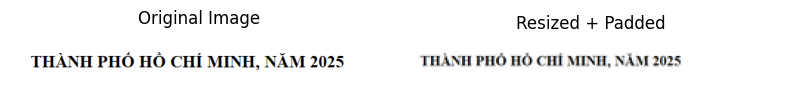

In [2]:
def auto_crop_whitespace(pil_img, threshold=200, pad=4):
    """Tự động cắt bỏ vùng lề trắng thừa xung quanh dòng chữ"""
    gray = pil_img.convert('L')

    img_np = np.array(gray)
    # Nếu nền sáng (trung bình > 127), đảo ngược để tìm vùng chữ đen
    if np.mean(img_np) > 127:
        mask = img_np < threshold
    else:
        mask = img_np > (255 - threshold)
        
    coords = np.argwhere(mask)
    if coords.size == 0:
        return pil_img
        
    y0, x0 = coords.min(axis=0)
    y1, x1 = coords.max(axis=0)
    
    # Chừa lại một viền nhỏ (pad=4 pixel) để không cắt lẹm vào dấu tiếng Việt
    h, w = img_np.shape
    y0 = max(0, y0 - pad)
    x0 = max(0, x0 - pad)
    y1 = min(h, y1 + pad)
    x1 = min(w, x1 + pad)
    
    return pil_img.crop((x0, y0, x1, y1))

def preprocess_auto_invert(image):
    """
    Chuyển ảnh sang grayscale và tự động đảo màu nếu nền tối, chữ sáng.
    """
    gray = image.convert('L')  # chuyển grayscale
    mean_brightness = np.array(gray).mean()

    # Nếu ảnh quá tối → khả năng nền tối, chữ sáng → đảo màu
    if mean_brightness < 127:
        gray = ImageOps.invert(gray)

    return gray

def resize_with_padding(image, target_size=(32, 256), pad_color=255):
    """
    Resize ảnh chuẩn cho Single-line OCR:
    - Cố định chiều cao theo target_h, giữ nguyên tỷ lệ ngang-dọc.
    - LUÔN CĂN TRÁI (paste_x = 0) để đồng bộ Positional Encoding.
    - Padding phần dư sang bên phải.
    """
    target_h, target_w = target_size
    original_w, original_h = image.size

    # 1. Luôn scale dựa trên chiều cao để chiều cao chữ luôn đạt target_h (ví dụ 32px)
    scale = target_h / float(original_h)
    new_h = target_h
    new_w = int(round(original_w * scale))

    # Nếu chiều rộng sau khi scale vượt quá target_w của khung, 
    # ta buộc phải scale theo chiều rộng để không bị cắt cụt chữ
    if new_w > target_w:
        scale = target_w / float(original_w)
        new_w = target_w
        new_h = max(1, int(round(original_h * scale)))

    # Resize ảnh với bộ lọc LANCZOS để giữ nét chữ sắc nét nhất
    resized_image = image.resize((new_w, new_h), Image.Resampling.LANCZOS)

    # 2. Tạo ảnh nền (mặc định màu trắng `255` cho ảnh văn bản thông thường)
    mode = image.mode
    if mode == 'L':
        fill = pad_color
    else:
        fill = (pad_color, pad_color, pad_color)
        
    new_image = Image.new(mode, (target_w, target_h), fill)
    
    # 3. CĂN TRÁI TUYỆT ĐỐI (paste_x = 0) giúp chữ đầu luôn ở vị trí pe[0]
    paste_x = 0  
    # Căn giữa theo chiều dọc nếu new_h nhỏ hơn target_h một chút (rất hiếm khi xảy ra)
    paste_y = (target_h - new_h) // 2  
    
    new_image.paste(resized_image, (paste_x, paste_y))

    return new_image

def load_and_resize_image(image_path, target_size=(32, 256), pad_color=255):
    """Load ảnh từ đường dẫn, trả về ảnh gốc và ảnh đã resize + padding."""
    original_image = Image.open(image_path).convert("RGB")
    resized_image = resize_with_padding(original_image, target_size=target_size, pad_color=pad_color)
    return original_image, resized_image

# Demo load và tiền xử lý ảnh mẫu (chỉ chạy nếu file tồn tại)
demo_sample_path = "/kaggle/input/datasets/quangle1502/image-test/nh chp mn hnh 2025-04-30 171020.png"
if os.path.exists(demo_sample_path):
    orig_img, resized_img = load_and_resize_image(demo_sample_path)
    plt.figure(figsize=(8, 3))
    plt.subplot(1, 2, 1); plt.title("Original Image"); plt.imshow(orig_img); plt.axis("off")
    plt.subplot(1, 2, 2); plt.title("Resized + Padded"); plt.imshow(resized_img); plt.axis("off")
    plt.tight_layout(); plt.show()


## 3. Định nghĩa Siêu tham số & Tập hợp Transforms


In [3]:
# Siêu tham số mô hình
batch_size = 32
d_model = 384
nhead = 8
num_decoder_layers = 3
dim_feedforward = 1024
dropout = 0.3
max_seq_length = 100

# Transforms cho validation và inference
val_transform = transforms.Compose([
    transforms.Lambda(auto_crop_whitespace),
    transforms.Lambda(preprocess_auto_invert),
    transforms.Lambda(resize_with_padding),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])
transform = val_transform

# Transforms cho tập huấn luyện với tăng cường dữ liệu
train_transform = transforms.Compose([
    transforms.Lambda(auto_crop_whitespace),
    transforms.Lambda(preprocess_auto_invert),
    transforms.Lambda(resize_with_padding),
    transforms.RandomAffine(degrees=2,
                            translate=(0.01, 0.05),
                            interpolation=transforms.InterpolationMode.BILINEAR,
                            fill=255),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])


## 4. Từ điển Ký tự (Vocabulary) & Mã hóa Nhãn (Label Encoding)


In [4]:
# Tạo từ điển ký tự
def build_vocab():
    """Tạo bộ từ điển chuyển đổi ký tự <-> index với chuẩn hóa NFC"""
    vocab = {}
    special_tokens = ['<pad>', '<sos>', '<eos>', '<unk>']
    for i, token in enumerate(special_tokens):
        vocab[token] = i
    
    # Bảng ký tự tiếng Việt đầy đủ hoa/thường, số và ký tự đặc biệt
    chars = r'''aáàạảãăắằặẳẵâấầậẩẫbcdđeéèẹẻẽêếềệểễfghiíìịỉĩjklmnoóòọỏõôốồộổỗơớờợởỡpqrstuúùụủũưứừựửữvwxyýỳỵỷỹzAÁÀẠẢÃĂẮẰẶẲẴÂẤẦẬẨẪBCDĐEÉÈẸẺẼÊẾỀỆỂỄFGHIÍÌỊỈĨJKLMNOÓÒỌỎÕÔỐỒỘỔỖƠỚỜỢỞỠPQRSTUÚÙỤỦŨƯỨỪỰỬỮVWXYÝỲỴỶỸZ0123456789!"#$%&'()*+,-./:;<=>?@[\]^_`{|}~ '''
    chars = unicodedata.normalize('NFC', chars)
    for char in chars:
        if char not in vocab:
            vocab[char] = len(vocab)
    
    return vocab

def label_to_indices(label, vocab, max_length=max_seq_length):
    """Chuyển đổi chuỗi nhãn thành chuỗi indices dạng tensor long"""
    label = unicodedata.normalize('NFC', str(label))
    indices = [vocab['<sos>']]
    
    for char in label:
        if char in vocab:
            indices.append(vocab[char])
        else:
            indices.append(vocab['<unk>'])
    
    indices.append(vocab['<eos>'])
    
    # Pad cho đủ độ dài
    if len(indices) < max_length:
        indices.extend([vocab['<pad>']] * (max_length - len(indices)))
    else:
        indices = indices[:max_length-1] + [vocab['<eos>']]
    
    return torch.tensor(indices, dtype=torch.long)

def create_inverse_vocab(vocab):
    """Tạo từ điển ngược từ index sang ký tự"""
    return {v: k for k, v in vocab.items()}

def indices_to_text(indices, vocab_inv, vocab):
    """Chuyển đổi chuỗi indices thành văn bản"""
    text = []
    eos_idx = vocab['<eos>']
    pad_idx = vocab['<pad>']
    sos_idx = vocab['<sos>']

    if isinstance(indices, torch.Tensor):
        indices = indices.tolist()

    for idx in indices:
        if idx == eos_idx:
            break
        elif idx in [pad_idx, sos_idx]:
            continue
        else:
            text.append(vocab_inv.get(idx, '?'))
    return ''.join(text)

vocab = build_vocab()
vocab_inv = create_inverse_vocab(vocab)
vocab_size = len(vocab)
print(f"Tổng số token trong Vocab (vocab_size): {vocab_size}")


Tổng số token trong Vocab (vocab_size): 233


## 5. Bộ Hậu Xử Lý Chính Tả Tiếng Việt (Vietnamese OCR Post-Processor)


In [5]:
def remove_accents(s):
    """Chuyển chuỗi tiếng Việt có dấu thành chuỗi không dấu chuẩn"""
    s = unicodedata.normalize('NFC', s).replace('đ', 'd').replace('Đ', 'D')
    nfkd = unicodedata.normalize('NFKD', s)
    return ''.join([c for c in nfkd if not unicodedata.combining(c)]).lower()

class VietnamesePostProcessor:
    """Bộ sửa lỗi chính tả và chuẩn hóa văn bản đầu ra cho OCR"""
    def __init__(self, data_file=None):
        self.words = set()
        self.word_freq = defaultdict(int)
        self.base_map = defaultdict(list)
        
        # Một số từ tiếng Việt thông dụng thường gặp
        default_words = [
            'cộng', 'hòa', 'xã', 'hội', 'chủ', 'nghĩa', 'việt', 'nam', 'độc', 'lập', 'tự', 'do', 'hạnh', 'phúc',
            'cửa', 'hàng', 'tạp', 'hóa', 'thực', 'phẩm', 'quán', 'ăn', 'cà', 'phê', 'nước', 'giải', 'khát',
            'địa', 'chỉ', 'điện', 'thoại', 'liên', 'hệ', 'khách', 'sạn', 'nhà', 'hàng', 'công', 'ty',
            'trách', 'nhiệm', 'hữu', 'hạn', 'biển', 'báo', 'giao', 'thông', 'cấm', 'dừng', 'đỗ', 'xe',
            'đường', 'một', 'chiều', 'nguy', 'hiểm', 'hóa', 'đơn', 'bán', 'hàng', 'ngày', 'tháng', 'năm',
            'tổng', 'tiền', 'thanh', 'toán', 'cảm', 'ơn', 'quý', 'khách'
        ]
        for w in default_words:
            self.add_word(w, count=10)
            
        if data_file and os.path.exists(data_file):
            self.load_from_file(data_file)

    def add_word(self, word, count=1):
        word = unicodedata.normalize('NFC', word.strip())
        if not word or any(ch.isdigit() for ch in word):
            return
        w_lower = word.lower()
        self.words.add(w_lower)
        self.word_freq[w_lower] += count
        base = remove_accents(w_lower)
        if w_lower not in self.base_map[base]:
            self.base_map[base].append(w_lower)

    def load_from_file(self, data_file):
        try:
            with open(data_file, 'r', encoding='utf-8') as f:
                for line in f:
                    parts = line.strip().split('\t')
                    if len(parts) >= 2:
                        label = unicodedata.normalize('NFC', parts[1])
                        for w in re.findall(r'\b[^\W\d_]+\b', label):
                            self.add_word(w)
            print(f"[PostProcessor] Đã học {len(self.words)} từ vựng từ {data_file}")
        except Exception as e:
            print(f"[PostProcessor] Lưu ý khi nạp file từ vựng: {e}")

    def correct_word(self, word):
        if not word or any(ch.isdigit() for ch in word) or len(word) <= 1:
            return word
        
        norm = unicodedata.normalize('NFC', word)
        lower = norm.lower()
        
        if lower in self.words:
            return norm
        
        # Tìm từ gần nhất thông qua gốc không dấu
        base = remove_accents(lower)
        candidates = self.base_map.get(base, [])
        if candidates:
            best = max(candidates, key=lambda c: self.word_freq[c])
            if norm.isupper(): return best.upper()
            if norm.istitle(): return best.capitalize()
            return best
        
        return norm

    def correct_text(self, text):
        if not text:
            return ""
        text = unicodedata.normalize('NFC', text)
        corrected = re.sub(r'\b[^\W\d_]+\b', lambda m: self.correct_word(m.group(0)), text)
        corrected = re.sub(r'\s+([,.:;?!])', r'\1', corrected)
        return re.sub(r'\s+', ' ', corrected).strip()

post_processor = VietnamesePostProcessor()
demo_raw = "cưa hàng tap hóa"
print(f"Ví dụ Post-Processor: '{demo_raw}' -> '{post_processor.correct_text(demo_raw)}'")


Ví dụ Post-Processor: 'cưa hàng tap hóa' -> 'cửa hàng tạp hóa'


## 6. Phân chia Dữ liệu & Khởi tạo Dataset, DataLoader

In [6]:
def split_txt_to_three_files(input_txt, train_txt, val_txt, test_txt,
                              train_ratio=0.7, val_ratio=0.2, test_ratio=0.1, seed=42):
    assert abs(train_ratio + val_ratio + test_ratio - 1.0) < 1e-6, "Tổng tỷ lệ phải bằng 1.0"
    with open(input_txt, 'r', encoding='utf-8') as f:
        lines = f.readlines()

    random.seed(seed)
    random.shuffle(lines)

    total = len(lines)
    train_end = int(train_ratio * total)
    val_end = train_end + int(val_ratio * total)

    train_lines = lines[:train_end]
    val_lines = lines[train_end:val_end]
    test_lines = lines[val_end:]

    with open(train_txt, 'w', encoding='utf-8') as f:
        f.writelines(train_lines)
    with open(val_txt, 'w', encoding='utf-8') as f:
        f.writelines(val_lines)
    with open(test_txt, 'w', encoding='utf-8') as f:
        f.writelines(test_lines)

    print(f"Tách xong: {len(train_lines)} train, {len(val_lines)} val, {len(test_lines)} test")

input_gt_file = '/kaggle/input/datasets/senju14/vietocr-vie-00/rec/rec_gt_train.txt'
train_txt = '/kaggle/working/train.txt'
val_txt = '/kaggle/working/val.txt'
test_txt = '/kaggle/working/test.txt'

if os.path.exists(input_gt_file):
    if not (os.path.exists(train_txt) and os.path.exists(val_txt)):
        split_txt_to_three_files(input_gt_file, train_txt, val_txt, test_txt)
        post_processor.load_from_file(train_txt)
    else:
        print("Các file dữ liệu train.txt, val.txt, test.txt đã sẵn sàng.")
        post_processor.load_from_file(train_txt)
else:
    print(f"Lưu ý: Không tìm thấy file {input_gt_file}. Nếu chạy trên Kaggle, hãy chắc chắn dataset đã được add.")

class OCRDataset(Dataset):
    def __init__(self, data_file, vocab, img_folder, transform=None):
        self.data = []
        self.vocab = vocab
        self.img_folder = img_folder
        self.transform = transform
        if os.path.exists(data_file):
            with open(data_file, 'r', encoding='utf-8') as f:
                for line in f.readlines():
                    if line.strip():
                        parts = line.strip().split('\t')
                        if len(parts) == 2:
                            image_filename, label = parts
                            self.data.append((image_filename, label))
        else:
            print(f"Không tìm thấy file: {data_file}")
    
    def __len__(self):
        return len(self.data)
    
    def __getitem__(self, idx):
        image_filename, label = self.data[idx]
        image_path = os.path.join(self.img_folder, image_filename)
        try:
            image = Image.open(image_path).convert('RGB')
        except Exception:
            image = Image.new('RGB', (256, 32), color=(0, 0, 0))
            
        if self.transform:
            image = self.transform(image)
        label_indices = label_to_indices(label, self.vocab)
        return image, label_indices

def collate_fn(batch):
    images, labels = zip(*batch)
    images = torch.stack(images, 0)
    labels = torch.stack(labels, 0)
    return images, labels


Tách xong: 70000 train, 20000 val, 10000 test
[PostProcessor] Đã học 35251 từ vựng từ /kaggle/working/train.txt


## 7. Kiến trúc Mô hình OCR Transformer
- **CNN_Backbone**: Trích xuất chuỗi đặc trưng thị giác từ ảnh đầu vào.
- **PositionalEncoding**: Mã hóa vị trí theo hàm Sin/Cos chuẩn.
- **`nn.TransformerDecoderLayer` & `nn.TransformerDecoder`**: Sử dụng trực tiếp lớp chuẩn PyTorch với `batch_first=True` giúp tối ưu hóa bộ nhớ và tốc độ thực thi.
- **OCRTransformer**: Tích hợp Encoder-Decoder và hỗ trợ cả Training (Teacher Forcing) lẫn Inference (Greedy Decode).


In [7]:
class CNN_Backbone(nn.Module):
    def __init__(self, d_model):
        super(CNN_Backbone, self).__init__()
        self.conv1 = nn.Conv2d(1, 64, kernel_size=3, stride=1, padding=1)
        self.bn1 = nn.BatchNorm2d(64)
        self.relu = nn.ReLU(inplace=True)
        
        # Pool 1 & 2: Giảm cả H và W đi 2 lần (Tổng cộng chia 4 theo chiều rộng)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        
        self.conv2 = nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1)
        self.bn2 = nn.BatchNorm2d(128)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)
        
        # Pool 3: Chỉ giảm chiều cao (H), GIỮ NGUYÊN chiều rộng (W) để không bị dính chữ
        self.conv3 = nn.Conv2d(128, 256, kernel_size=3, stride=1, padding=1)
        self.bn3 = nn.BatchNorm2d(256)
        self.pool3 = nn.MaxPool2d(kernel_size=(2, 1), stride=(2, 1))
        
        self.conv4 = nn.Conv2d(256, d_model, kernel_size=3, stride=1, padding=1)
        self.bn4 = nn.BatchNorm2d(d_model)
        
        # Gộp chiều cao (H) về đúng bằng 1 bất kể kích thước ảnh đầu vào
        self.adaptive_pool = nn.AdaptiveAvgPool2d((1, None))
        self.dropout = nn.Dropout(p=0.1)
        
    def forward(self, x):
        x = self.pool1(self.relu(self.bn1(self.conv1(x))))
        x = self.pool2(self.relu(self.bn2(self.conv2(x))))
        x = self.pool3(self.relu(self.bn3(self.conv3(x))))
        x = self.relu(self.bn4(self.conv4(x)))
        
        # Đưa chiều cao H về 1 -> Kích thước: (Batch, d_model, 1, W_feat)
        x = self.adaptive_pool(x)
        x = self.dropout(x)
        
        # Bỏ chiều H=1 và đảo chiều thành (Batch, W_feat, d_model)
        features = x.squeeze(2).permute(0, 2, 1)
        return features


class PositionalEncoding(nn.Module):
    def __init__(self, d_model, dropout=0.1, max_len=1000):
        super(PositionalEncoding, self).__init__()
        self.dropout = nn.Dropout(p=dropout)
        
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        
        # Shape chuẩn cho batch_first=True: (1, max_len, d_model)
        pe = pe.unsqueeze(0)
        self.register_buffer('pe', pe)
    
    def forward(self, x):
        # x có shape: (Batch_size, Seq_len, d_model)
        x = x + self.pe[:, :x.size(1), :]
        return self.dropout(x)


class OCRTransformer(nn.Module):
    def __init__(self, vocab_size, d_model, nhead, num_decoder_layers, 
                 dim_feedforward, dropout, max_seq_length, sos_idx, eos_idx):
        super(OCRTransformer, self).__init__()
        self.d_model = d_model
        self.max_seq_length = max_seq_length
        self.sos_idx = sos_idx
        self.eos_idx = eos_idx
        
        self.backbone = CNN_Backbone(d_model)
        self.pos_encoder = PositionalEncoding(d_model=d_model, max_len=1000, dropout=dropout)
        self.token_embedding = nn.Embedding(vocab_size, d_model, padding_idx=0)
        
        decoder_layer = nn.TransformerDecoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True
        )
        self.decoder = nn.TransformerDecoder(
            decoder_layer=decoder_layer,
            num_layers=num_decoder_layers
        )
        self.output_layer = nn.Linear(d_model, vocab_size)
        self.apply(self._init_weights)
        
    def _init_weights(self, module):
        if isinstance(module, (nn.Linear, nn.Embedding)):
            module.weight.data.normal_(mean=0.0, std=0.02)
            if isinstance(module, nn.Linear) and module.bias is not None:
                module.bias.data.zero_()
            if isinstance(module, nn.Embedding) and module.padding_idx is not None:
                module.weight.data[module.padding_idx].zero_()
        elif isinstance(module, nn.LayerNorm):
            module.bias.data.zero_()
            module.weight.data.fill_(1.0)

    def create_memory_mask(self, src, memory_len):
        """
        Tạo memory_key_padding_mask từ ảnh gốc `src` (B, C, H, W):
        - Tìm cột cuối cùng có chứa nét chữ trên ảnh gốc.
        - Chỉ mask phần Padding nằm BÊN PHẢI nét chữ cuối cùng (bảo toàn khoảng trắng giữa các từ).
        - Quy đổi sang độ dài `memory_len` tương ứng sau khi qua CNN.
        """
        _, _, _, W = src.size()
        device = src.device

        # 1. Tìm các cột trên ảnh gốc có chứa nét chữ (độ lệch chuẩn theo chiều dọc H > 1e-4)
        col_std = src.mean(dim=1).std(dim=1)  # Shape: (Batch, W)
        has_text = (col_std > 1e-4)           # True ở cột có nét chữ, False ở cột màu nền đồng nhất

        # 2. Tìm chỉ số cột cuối cùng có chữ cho từng ảnh trong Batch
        col_indices = torch.arange(W, device=device).unsqueeze(0)  # (1, W)
        last_text_col = torch.where(has_text, col_indices, torch.tensor(-1, device=device)).max(dim=1)[0]

        # Độ rộng hợp lệ tính bằng pixel trên ảnh gốc (tối thiểu là 1 để tránh lỗi NaN)
        valid_widths = (last_text_col + 1).clamp(min=1)  # Shape: (Batch,)

        # 3. Quy đổi sang độ dài trên `memory` sau khi bị CNN nén (W / memory_len = 4)
        downsample_ratio = W / float(memory_len)
        # Làm tròn lên và cộng 1 cột đệm an toàn để không cắt lẹm Receptive Field của chữ cuối
        valid_memory_lens = torch.ceil(valid_widths.float() / downsample_ratio).long() + 1
        valid_memory_lens = valid_memory_lens.clamp(max=memory_len)  # Shape: (Batch,)

        # 4. Tạo mask kiểu bool (True tại các vị trí padding bên phải cần che đi)
        mem_indices = torch.arange(memory_len, device=device).unsqueeze(0)  # (1, memory_len)
        memory_padding_mask = mem_indices >= valid_memory_lens.unsqueeze(1) # (Batch, memory_len)

        return memory_padding_mask

    def create_mask(self, tgt):
        tgt_seq_len = tgt.size(1)
        tgt_mask = torch.triu(
            torch.ones((tgt_seq_len, tgt_seq_len), device=tgt.device, dtype=torch.bool), 
            diagonal=1
        )
        tgt_padding_mask = (tgt == 0)
        return tgt_mask, tgt_padding_mask

    def forward(self, src, tgt=None):
        memory = self.backbone(src)
        memory = self.pos_encoder(memory)
        memory_key_padding_mask = self.create_memory_mask(src, memory.size(1))
    
        if tgt is not None:
            tgt_embeddings = self.token_embedding(tgt) * math.sqrt(self.d_model)
            tgt_embeddings = self.pos_encoder(tgt_embeddings)
            tgt_mask, tgt_padding_mask = self.create_mask(tgt)

            output = self.decoder(
                tgt=tgt_embeddings,
                memory=memory,
                tgt_mask=tgt_mask,
                tgt_key_padding_mask=tgt_padding_mask,
                memory_key_padding_mask=memory_key_padding_mask
            )
            return self.output_layer(output)
        else:
            return self.greedy_decode(memory, memory_key_padding_mask, max_len=self.max_seq_length)

    def greedy_decode(self, memory, memory_key_padding_mask=None, max_len=50):
        device = memory.device
        batch_size = memory.size(0)
        ys = torch.full((batch_size, 1), self.sos_idx, dtype=torch.long, device=device)
        finished = torch.zeros(batch_size, dtype=torch.bool, device=device)
    
        for _ in range(max_len - 1):
            tgt_emb = self.token_embedding(ys) * math.sqrt(self.d_model)
            tgt_emb = self.pos_encoder(tgt_emb)
            tgt_mask, tgt_padding_mask = self.create_mask(ys)
    
            out = self.decoder(
                tgt=tgt_emb, 
                memory=memory, 
                tgt_mask=tgt_mask, 
                tgt_key_padding_mask=tgt_padding_mask,
                memory_key_padding_mask=memory_key_padding_mask
            )
            prob = self.output_layer(out[:, -1, :])
            next_word = prob.argmax(dim=-1, keepdim=True)
            ys = torch.cat([ys, next_word], dim=1)
            
            finished |= (next_word.squeeze(1) == self.eos_idx)
            if finished.all():
                break
    
        return ys

## 8. Các Hàm Huấn Luyện (Training) & Đánh Giá (Evaluation)
- **Tự động lưu checkpoint**:
  - `best_ocr_model.pth`: Lưu trọng số tốt nhất (Validation Accuracy cao nhất).
  - `final_ocr_model.pth`: Lưu trọng số ở epoch cuối cùng sau khi kết thúc quá trình huấn luyện.


In [8]:
def evaluate(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device)
            labels = labels.to(device)

            tgt_inp = labels[:, :-1]
            tgt_out = labels[:, 1:]

            output = model(images, tgt_inp)
            output_reshaped = output.view(-1, output.size(-1))
            tgt_out_reshaped = tgt_out.reshape(-1)
            loss = criterion(output_reshaped, tgt_out_reshaped)
            total_loss += loss.item()

            preds = output.argmax(dim=-1)
            mask = tgt_out != 0
            correct += ((preds == tgt_out) & mask).sum().item()
            total += mask.sum().item()

    avg_loss = total_loss / len(dataloader) if len(dataloader) > 0 else 0
    accuracy = correct / total if total > 0 else 0
    return avg_loss, accuracy

def test_examples(model, dataloader, vocab, device, post_processor=None, num_examples=5):
    """Kiểm tra trực quan một số ví dụ, so sánh Raw OCR và Post-processed OCR"""
    model.eval()
    vocab_inv = create_inverse_vocab(vocab)
    all_examples = []
    
    with torch.no_grad():
        for images, labels in dataloader:
            if len(all_examples) >= num_examples:
                break
            images = images.to(device)
            output_sequences = model(images)
            
            for i in range(min(len(images), num_examples - len(all_examples))):
                true_text = indices_to_text(labels[i], vocab_inv, vocab)
                pred_indices = output_sequences[i]
                raw_pred = indices_to_text(pred_indices, vocab_inv, vocab)
                corrected_pred = post_processor.correct_text(raw_pred) if post_processor else raw_pred
                all_examples.append((true_text, raw_pred, corrected_pred))
    
    print("\nKết quả kiểm tra mẫu:")
    print("-" * 60)
    for i, (true_t, raw_p, corr_p) in enumerate(all_examples):
        print(f"Ví dụ {i+1}:")
        print(f"  Thực tế (Ground Truth) : {true_t}")
        print(f"  Dự đoán thô (Raw OCR)  : {raw_p}")
        print(f"  Sau Hậu xử lý (Sửa lỗi): {corr_p}")
        print(f"  Khớp chính xác         : {'✓' if (true_t == corr_p) else '✗'}")
        print("-" * 60)

def progressive_train(model, train_loader, val_loader, optimizer, scheduler, criterion, device, num_epochs=30, eval_every=1):
    history = {'train_loss': [], 'val_loss': [], 'val_accuracy': []}
    best_val_loss = float('inf')
    best_val_accuracy = 0
    
    print("Bắt đầu huấn luyện:")
    for epoch in range(num_epochs):
        model.train()
        total_train_loss = 0
        for batch_idx, (images, labels) in enumerate(train_loader):
            images = images.to(device)
            labels = labels.to(device)
            
            tgt_inp = labels[:, :-1]
            tgt_out = labels[:, 1:]
            
            output = model(images, tgt_inp)
            output = output.view(-1, output.size(-1))
            tgt_out = tgt_out.reshape(-1)
            
            loss = criterion(output, tgt_out)
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()
            
            total_train_loss += loss.item()
        
        avg_train_loss = total_train_loss / len(train_loader) if len(train_loader) > 0 else 0
        history['train_loss'].append(avg_train_loss)
        
        if (epoch + 1) % eval_every == 0:
            val_loss, val_accuracy = evaluate(model, val_loader, criterion, device)
            history['val_loss'].append(val_loss)
            history['val_accuracy'].append(val_accuracy)
            
            print(f"Epoch [{epoch+1}/{num_epochs}] | Train Loss: {avg_train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_accuracy:.2%}")
            
            # Lưu trọng số mô hình tốt nhất
            if val_accuracy > best_val_accuracy:
                best_val_accuracy = val_accuracy
                torch.save(model.state_dict(), 'best_ocr_model.pth')
                print(f" -> Đã lưu checkpoint tốt nhất tại epoch {epoch+1} với Acc: {val_accuracy:.2%}")
            
            scheduler.step(val_loss)
    
    # Lưu trọng số mô hình ở epoch cuối cùng
    torch.save(model.state_dict(), 'final_ocr_model.pth')
    print(" -> Đã lưu checkpoint epoch cuối cùng thành công: final_ocr_model.pth")
    return history


## 9. Huấn luyện Mô hình Chính (Run Training)
- Tự động train và lưu checkpoint `best_ocr_model.pth` và `final_ocr_model.pth`.
- Sau khi train xong, tự động nạp `best_ocr_model.pth` để đánh giá trên tập kiểm tra.


In [9]:
# Khởi tạo mô hình OCRTransformer
ocr_model = OCRTransformer(
    vocab_size=len(vocab),
    d_model=d_model,
    nhead=nhead,
    num_decoder_layers=num_decoder_layers,
    dim_feedforward=dim_feedforward,
    dropout=dropout,
    max_seq_length=max_seq_length,
    sos_idx=vocab['<sos>'],
    eos_idx=vocab['<eos>']
).to(device)

total_params = sum(p.numel() for p in ocr_model.parameters() if p.requires_grad)
print(f"Tổng số tham số có thể huấn luyện: {total_params:,}")

# Kiểm tra dữ liệu huấn luyện
data_root = '/kaggle/input/datasets/senju14/vietocr-vie-00/rec'
should_train = os.path.exists(train_txt) and os.path.exists(data_root)

if should_train:
    train_dataset = OCRDataset(data_file=train_txt, vocab=vocab, img_folder=data_root, transform=train_transform)
    val_dataset = OCRDataset(data_file=val_txt, vocab=vocab, img_folder=data_root, transform=val_transform)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=4, collate_fn=collate_fn, drop_last=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=4, collate_fn=collate_fn)

    criterion = nn.CrossEntropyLoss(ignore_index=0, label_smoothing=0.1)
    optimizer = optim.AdamW(ocr_model.parameters(), lr=5e-4, betas=(0.9, 0.98), eps=1e-9, weight_decay=0.01)
    scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

    # Huấn luyện mô hình (giảm số epochs nếu muốn chạy nhanh)
    num_epochs = 150
    history = progressive_train(
        model=ocr_model,
        train_loader=train_loader,
        val_loader=val_loader,
        optimizer=optimizer,
        scheduler=scheduler,
        criterion=criterion,
        device=device,
        num_epochs=num_epochs,
        eval_every=1
    )
    
    # Nạp lại mô hình tốt nhất vừa lưu để đánh giá
    if os.path.exists('best_ocr_model.pth'):
        ocr_model.load_state_dict(torch.load('best_ocr_model.pth', map_location=device))
        print("Đã nạp lại trọng số tốt nhất (best_ocr_model.pth) sau khi huấn luyện.")
    
    test_examples(ocr_model, val_loader, vocab, device, post_processor=post_processor, num_examples=5)

else:
    # Nếu không tìm thấy tập train, thử nạp pretrained model
    checkpoint_candidates = ['best_ocr_model.pth', '/kaggle/working/best_ocr_model.pth', '/kaggle/input/new-model/best_ocr_model.pth']
    loaded = False
    for p in checkpoint_candidates:
        if os.path.exists(p):
            ocr_model.load_state_dict(torch.load(p, map_location=device, weights_only=True))
            print(f"Đã nạp trọng số có sẵn từ: {p}")
            loaded = True
            break
    if not loaded:
        print("Không có sẵn tập train và checkpoint. Sẽ sử dụng mô hình khởi tạo ngẫu nhiên để minh họa luồng pipeline.")


Tổng số tham số có thể huấn luyện: 7,354,217
Bắt đầu huấn luyện:
Epoch [1/150] | Train Loss: 2.6838 | Val Loss: 2.0979 | Val Acc: 61.45%
 -> Đã lưu checkpoint tốt nhất tại epoch 1 với Acc: 61.45%
Epoch [2/150] | Train Loss: 2.0288 | Val Loss: 1.6640 | Val Acc: 76.35%
 -> Đã lưu checkpoint tốt nhất tại epoch 2 với Acc: 76.35%
Epoch [3/150] | Train Loss: 1.7781 | Val Loss: 1.5113 | Val Acc: 81.60%
 -> Đã lưu checkpoint tốt nhất tại epoch 3 với Acc: 81.60%
Epoch [4/150] | Train Loss: 1.6580 | Val Loss: 1.4517 | Val Acc: 83.73%
 -> Đã lưu checkpoint tốt nhất tại epoch 4 với Acc: 83.73%
Epoch [5/150] | Train Loss: 1.5874 | Val Loss: 1.4040 | Val Acc: 85.33%
 -> Đã lưu checkpoint tốt nhất tại epoch 5 với Acc: 85.33%
Epoch [6/150] | Train Loss: 1.5406 | Val Loss: 1.3537 | Val Acc: 86.88%
 -> Đã lưu checkpoint tốt nhất tại epoch 6 với Acc: 86.88%
Epoch [7/150] | Train Loss: 1.5032 | Val Loss: 1.3238 | Val Acc: 87.81%
 -> Đã lưu checkpoint tốt nhất tại epoch 7 với Acc: 87.81%
Epoch [8/150] | Tr

## 10. Dự đoán Mẫu Đơn Lẻ (Single Image Prediction)


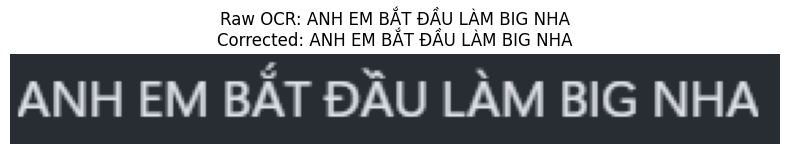

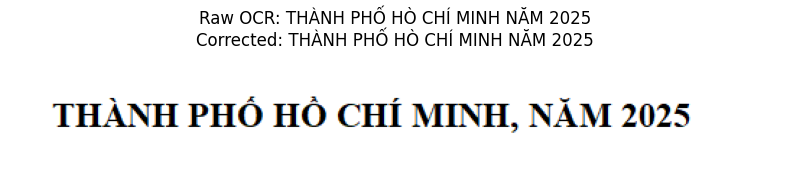

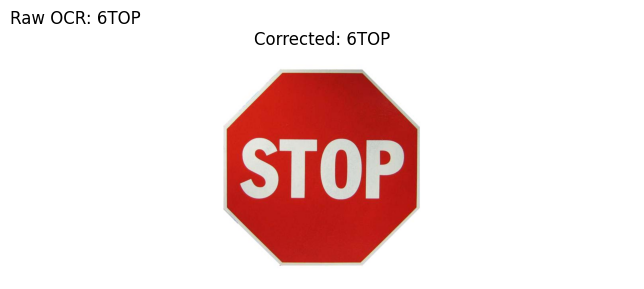

In [10]:
def predict_single_image_with_plot(image_path, model, vocab, device, post_processor=None):
    """Dự đoán một ảnh chữ đơn lẻ và hiển thị kết quả trước & sau khi sửa lỗi"""
    if not os.path.exists(image_path):
        print(f"Không tìm thấy ảnh: {image_path}")
        return None
        
    vocab_inv = {idx: token for token, idx in vocab.items()}
    original_image = Image.open(image_path).convert('RGB')
    image_tensor = val_transform(original_image).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        output_sequence = model(image_tensor)
        raw_text = indices_to_text(output_sequence[0].tolist(), vocab_inv, vocab)
        
    corrected_text = post_processor.correct_text(raw_text) if post_processor else raw_text

    plt.figure(figsize=(8, 3))
    plt.imshow(original_image)
    plt.title(f"Raw OCR: {raw_text}\nCorrected: {corrected_text}", fontsize=12)
    plt.axis('off')
    plt.tight_layout()
    plt.show()

    return corrected_text

ocr_model = OCRTransformer(
    vocab_size=len(vocab),
    d_model=d_model,
    nhead=nhead,
    num_decoder_layers=num_decoder_layers,
    dim_feedforward=dim_feedforward,
    dropout=dropout,
    max_seq_length=max_seq_length,
    sos_idx=vocab['<sos>'],
    eos_idx=vocab['<eos>']
).to(device)

ocr_model.load_state_dict(torch.load('/kaggle/input/datasets/quangle1502/ocr-model/best_ocr_model.pth', map_location=device))

# Thử nghiệm trên ảnh mẫu (nếu tồn tại)
test_single_paths = [
    '/kaggle/input/datasets/quangle1502/image-test/nh chp mn hnh 2025-05-02 144448.png',
    '/kaggle/input/datasets/quangle1502/image-test/nh chp mn hnh 2025-04-30 171020.png',
    '/kaggle/input/datasets/quangle1502/image-test/bien-bao-da-giac.jpg'
]
for p in test_single_paths:
    if os.path.exists(p):
        predict_single_image_with_plot(p, ocr_model, vocab, device, post_processor=post_processor)


## 11. Tải và Thiết lập CRAFT Text Detector


In [11]:
import os
os.system("pip install -q easyocr")

from collections import namedtuple
import numpy as np
import torch
from PIL import Image
import easyocr

BoxResult = namedtuple("BoxResult", ["box", "image"])

class ModernCRAFTDetector:
    def __init__(self, cuda=True):
        # Tắt recognizer (recognizer=False) để chỉ tải và chạy duy nhất model CRAFT Detector
        self.reader = easyocr.Reader(
            ['vi', 'en'], 
            gpu=(cuda and torch.cuda.is_available()), 
            recognizer=False,
             detector=True
        )
        print("[INFO] Modern CRAFT Detector (qua EasyOCR) đã sẵn sàng.")

    def detect(self, image_input, canvas_size=1400, mag_ratio=1.4, text_threshold=0.6, link_threshold=0.3, low_text=0.3):
        if isinstance(image_input, str):
            img = np.array(Image.open(image_input).convert('RGB'))
        elif isinstance(image_input, Image.Image):
            img = np.array(image_input.convert('RGB'))
        else:
            img = image_input

        # Hàm detect của EasyOCR chạy CRAFT bên dưới và tự động gộp các từ gần nhau thành dòng
        horizontal_list, _ = self.reader.detect(
            img,
            canvas_size=canvas_size,
            mag_ratio=mag_ratio,
            text_threshold=text_threshold,
            link_threshold=link_threshold,
            low_text=low_text,
            width_ths=0.5, # Độ nhạy khi gộp các box gần nhau theo chiều ngang (thay cho merge_boxes)
            ycenter_ths=0.5
        )

        if not horizontal_list or len(horizontal_list[0]) == 0:
            return []

        cropped_images = []
        img_h, img_w = img.shape[:2]
        
        # Mỗi phần tử trong horizontal_list[0] có định dạng [x_min, x_max, y_min, y_max]
        for b in horizontal_list[0]:
            x_min, x_max, y_min, y_max = map(int, b)
            extend_x, extend_y = 15, 10
            
            x_start = max(0, x_min)
            y_start = max(0, y_min)
            x_end = min(x_max + extend_x, img_w)
            y_end = min(y_max + extend_y, img_h)

            crop = img[y_start:y_end, x_start:x_end]
            new_box = [[x_start, y_start], [x_end, y_start], [x_end, y_end], [x_start, y_end]]
            cropped_images.append(BoxResult(box=new_box, image=crop))

        return cropped_images

craft_detector = ModernCRAFTDetector(cuda=True)

[INFO] Modern CRAFT Detector (qua EasyOCR) đã sẵn sàng.


## 12. Pipeline OCR Hoàn Chỉnh: CRAFT Detector + Transformer Recognizer + Post-Processor


Các dòng chữ nhận diện được:
  1. Bách hóa Nguyên Nhà T
  2. 51B Trần Qu Trần Qu Trân Qu Trân
  3. Biểu.Ph3.Quận 3 I Duẩn 3 Tỷ 1 Triệu: Ph3.000 Diệu;
  4. 0T: 0938.833.154 - 0938-1838-1838-0938-1838-1838-187:
  5. Exitine


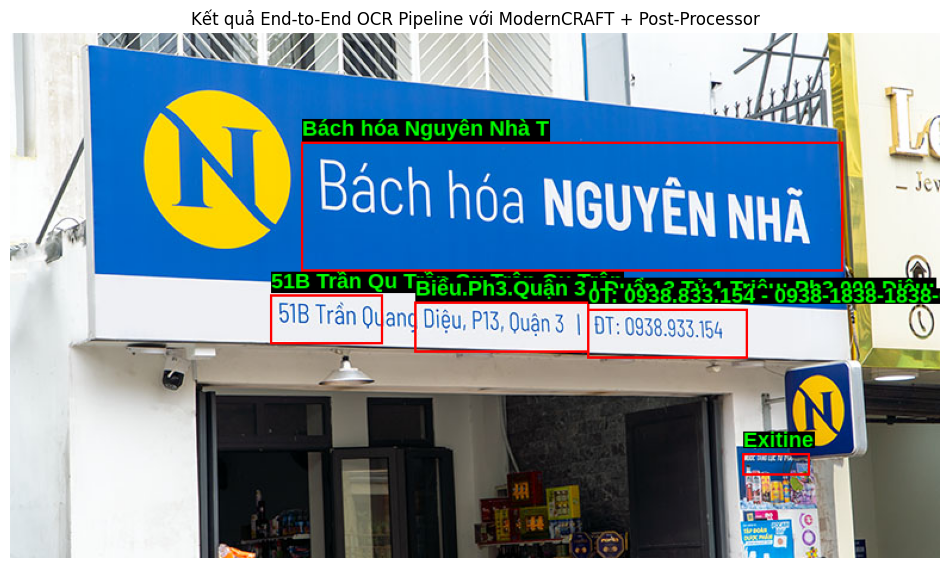

In [12]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont
from torchvision import transforms

class OCRPipeline:
    def __init__(self, detector, ocr_model, vocab, device, post_processor=None,
                 target_size=(32, 256), fill_color=(0, 0, 0)):
        self.detector = detector
        self.ocr_model = ocr_model.to(device)
        self.ocr_model.eval()
        self.vocab = vocab
        self.device = device
        self.post_processor = post_processor
        self.target_size = target_size
        self.fill_color = fill_color
        self.vocab_inv = {v: k for k, v in vocab.items()}

        self.transform = transforms.Compose([
            transforms.Lambda(lambda img: auto_crop_whitespace(img)),
            transforms.Lambda(lambda img: resize_with_padding(img, self.target_size)),
            transforms.Lambda(preprocess_auto_invert),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.5], std=[0.5])
        ])

        # Tự động nạp font hỗ trợ Unicode/Tiếng Việt trên Kaggle (Ubuntu)
        self.font = self._load_vietnamese_font(size=18)

    def _load_vietnamese_font(self, size=18):
        font_paths = [
            "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf",
            "/usr/share/fonts/truetype/liberation/LiberationSans-Bold.ttf",
            "/usr/share/fonts/truetype/freefont/FreeSansBold.ttf"
        ]
        for path in font_paths:
            if os.path.exists(path):
                return ImageFont.truetype(path, size=size)
        return ImageFont.load_default()

    def indices_to_text(self, indices):
        tokens = []
        for idx in indices:
            token = self.vocab_inv.get(int(idx), '')
            if token == '<eos>':
                break
            if token not in ['<pad>', '<sos>', '<eos>']:
                tokens.append(token)
        return ''.join(tokens)

    @torch.inference_mode()
    def predict_batch(self, pil_images):
        """Dự đoán cùng lúc một batch các vùng ảnh đã cắt để tối ưu tốc độ GPU."""
        if not pil_images:
            return []

        tensors = [self.transform(img) for img in pil_images]
        batch_tensor = torch.stack(tensors).to(self.device)

        output_seqs = self.ocr_model(batch_tensor)

        results = []
        for seq in output_seqs:
            raw_text = self.indices_to_text(seq.tolist())
            if self.post_processor:
                raw_text = self.post_processor.correct_text(raw_text)
            results.append(raw_text)
        return results

    def predict_text(self, image_pil):
        """Giữ lại hàm dự đoán đơn lẻ để tương thích ngược."""
        return self.predict_batch([image_pil])[0]

    def __call__(self, image_input, return_details=False):
        # 1. Chuẩn hóa đầu vào (Hỗ trợ đường dẫn file, mảng NumPy hoặc ảnh PIL)
        if isinstance(image_input, str):
            image = Image.open(image_input).convert('RGB')
        elif isinstance(image_input, np.ndarray):
            image = Image.fromarray(image_input).convert('RGB')
        else:
            image = image_input.convert('RGB').copy()

        # 2. Phát hiện vùng chữ bằng ModernCRAFTDetector (Cách 2)
        crops = self.detector.detect(image)
        if not crops:
            return (image, []) if return_details else image

        # Lọc bỏ các box rỗng hoặc kích thước bằng 0
        valid_boxes = []
        valid_pil_crops = []
        for item in crops:
            if item.image is not None and item.image.size > 0 and item.image.shape[0] > 0 and item.image.shape[1] > 0:
                valid_boxes.append(item.box)
                valid_pil_crops.append(Image.fromarray(item.image))

        if not valid_pil_crops:
            return (image, []) if return_details else image

        # 3. Nhận diện toàn bộ vùng chữ trong 1 lần gọi (Batch Inference)
        predicted_texts = self.predict_batch(valid_pil_crops)

        # 4. Vẽ kết quả lên ảnh
        draw = ImageDraw.Draw(image)
        extracted_data = []

        for box, text in zip(valid_boxes, predicted_texts):
            extracted_data.append({"box": box, "text": text})

            # Vẽ khung viền đỏ quanh chữ
            polygon_pts = [tuple(map(int, pt)) for pt in box + [box[0]]]
            draw.line(polygon_pts, fill=(255, 0, 0), width=2)

            # Tính toán vị trí vẽ nhãn chữ có nền đen mờ để dễ đọc
            x_min = int(min(p[0] for p in box))
            y_min = int(min(p[1] for p in box))
            text_y = max(0, y_min - 22)

            # Vẽ hộp nền đen phía dưới chữ
            bbox_text = draw.textbbox((x_min, text_y), str(text), font=self.font)
            draw.rectangle(bbox_text, fill=(0, 0, 0))
            
            # Vẽ chữ tiếng Việt màu xanh lá
            draw.text((x_min, text_y), str(text), fill=(0, 255, 0), font=self.font)

        if return_details:
            return image, extracted_data
        return image

# Khởi tạo pipeline hoàn chỉnh với ModernCRAFTDetector
ocr_pipeline = OCRPipeline(
    detector=craft_detector,
    ocr_model=ocr_model,
    vocab=vocab,
    device=device,
    post_processor=post_processor
)

# Chạy thử nghiệm
demo_scene_image = "/kaggle/input/datasets/quangle1502/image-test/bang-hieu-tap-hoa-1-780x440.jpg"
if os.path.exists(demo_scene_image):
    result_img, details = ocr_pipeline(demo_scene_image, return_details=True)
    
    print("Các dòng chữ nhận diện được:")
    for idx, item in enumerate(details, 1):
        print(f"  {idx}. {item['text']}")

    plt.figure(figsize=(12, 8))
    plt.imshow(result_img)
    plt.title("Kết quả End-to-End OCR Pipeline với ModernCRAFT + Post-Processor")
    plt.axis('off')
    plt.show()
else:
    print(f"Ảnh demo {demo_scene_image} chưa có sẵn. Bạn có thể truyền ảnh bất kỳ vào ocr_pipeline(img) để nhận diện.")